## 3.1 · Build the article dataframe


In [2]:
from pathlib import Path, PurePosixPath
import re, zipfile, html, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import NMF
from sklearn.preprocessing import normalize

path = next(p for p in (Path('data/research_corpus.zip'), Path('../data/research_corpus.zip'), Path('research_corpus.zip'), Path('upload/research_corpus.zip')) if p.exists())
with zipfile.ZipFile(path) as archive:
    names = sorted((n for n in archive.namelist() if n.lower().endswith('.txt')),
                   key=lambda n: int(re.search(r'(\d+)\.txt$', n).group(1)))
    articles = pd.DataFrame([{'article': i, 'filename': PurePosixPath(n).name,
                              'content': archive.read(n).decode('utf-8-sig')}
                             for i, n in enumerate(names, 1)]).set_index('article')
print(articles.assign(characters=articles.content.str.len(),
                      opening=articles.content.str.replace(r'\s+', ' ', regex=True).str[:65])
      [['filename', 'characters', 'opening']].to_string())

               filename  characters                                                            opening
article                                                                                               
1        research_1.txt       38598  The purposes of this article are to position mixed methods resear
2        research_2.txt       16279  Now I see it, now I don’t: researcher’s position and reflexivity 
3        research_3.txt       26521  DEVELOPMENTAL RESEARCH: STUDIES OF INSTRUCTIONAL DESIGN AND DEVEL
4        research_4.txt       39072  Abstract Cronbach’s alpha is a statistic commonly quoted by autho
5        research_5.txt       27142  Denzin’s Paradigm Shift: Revisiting Triangulation in Qualitative 


## 3.2 · Denoise the extracted text


In [3]:
front_matter = {2: 'Abstract', 3: '41.1 INTRODUCTION', 5: 'One approach to promote'}
layout = re.compile(r'^(?:\d+|abstract|article|Berger \d+|\d+ Qualitative Research.*|'
                    r'Fusch, Fusch, & Ness, 2018|Journal of Social Change \d+|'
                    r'\d+ EDUCATIONAL RESEARCHER|OCTOBER 2004 \d+|\d+ • RICHEY.*|'
                    r'Mixed Methods Research:|A Research Paradigm Whose Time Has Come|'
                    r'by R\. Burke Johnson.*|41\.\d+(?:\.\d+)* [A-Z][^.]{0,65})$', re.I)
def denoise(article, raw):
    text = unicodedata.normalize('NFKC', html.unescape(raw)).replace('\r\n', '\n')
    text = re.sub(r'[\x00-\x09\x0b-\x1f\xad]', ' ', text)
    if article in front_matter:
        text = text[text.index(front_matter[article]):]
    text = re.sub(r'(?m)^Corresponding author:.*?^Article\s*$', '', text, flags=re.S)
    text = re.sub(r'(?m)^Keywords\s*\n[^\n]+|^Keywords:.*?\nIntroduction\b', '', text, flags=re.S)
    text = '\n'.join(l for l in text.splitlines() if not layout.fullmatch(l.strip()))
    text = re.sub(r'(?<=\w)-\n(?=[a-z])', '', text)
    text = re.sub(r'https?://\S+|[\w.+-]+@[\w.-]+\.[a-z]+', ' ', text)
    text = re.sub(r'Educational Researcher, Vol\. 33, No\. 7, pp\. 14–26', ' ', text)
    text = ' '.join(text.split())
    cut = text.find(text[:100], 100)
    doubled = cut > 0 and text[:cut].strip() == text[cut:].strip()
    if doubled:
        text = text[:cut].strip()
    text = re.sub(r'\([^()]*(?:19|20)\d{2}[^()]*\)', '', text)
    text = re.sub(r'(?<=[.!?])\d{1,2}(?=\s+[A-Z])', '', text)
    text = re.sub(r'(?<=[a-z][.!?])(?=[A-Z])', ' ', text)
    text = re.sub(r'\s+([,.;:])', r'\1', ' '.join(text.split()))
    return text, doubled

def split_sentences(text):
    protected = re.sub(r'\b(?:e\.g\.|i\.e\.|et al\.|Fig\.|Dr\.)',
                       lambda m: m[0].replace('.', '∯'), text, flags=re.I)
    return [s.replace('∯', '.').strip() for s in re.split(r'(?<=[.!?])\s+(?=[“"‘(A-Z])', protected) if s]

cleaned = [denoise(i, row.content) for i, row in articles.iterrows()]
articles['clean'] = [x[0] for x in cleaned]
articles['sentences'] = articles.clean.map(split_sentences)
audit = pd.DataFrame({'raw_words': articles.content.str.split().str.len(),
                      'clean_words': articles.clean.str.split().str.len(),
                      'sentences': articles.sentences.str.len(),
                      'repeated_copy_removed': [x[1] for x in cleaned]})
assert articles.clean.str.len().gt(0).all()
print(audit.to_string())
# Filter common words only in the feature matrix. Retain negation.
stop = sorted(set(ENGLISH_STOP_WORDS) - {'no', 'not', 'never', 'without'})
def vectorizer(**kwargs):
    return TfidfVectorizer(stop_words=stop, ngram_range=(1, 2), sublinear_tf=True, **kwargs)

         raw_words  clean_words  sentences  repeated_copy_removed
article                                                          
1             5602         2597         75                   True
2             2416         2181         58                  False
3             3828         3610        159                  False
4             5922         5764        177                  False
5             4027         3601        159                  False


## 3.3 · First article: TextRank extractive summary


S1: The purposes of this article are to position mixed methods research (mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting mixed methods research.

S23: We hope the field will move beyond quantitative versus qualitative research arguments because, as recognized by mixed methods research, both quantitative and qualitative research are important and useful.

S28: Mixed methods research as the third research paradigm can also help bridge the schism between quantitative and qualitative research.

S43: For example, qualitative researchers should be free to use quantitative methods, and quantitative researchers should be free to use qualitative methods.



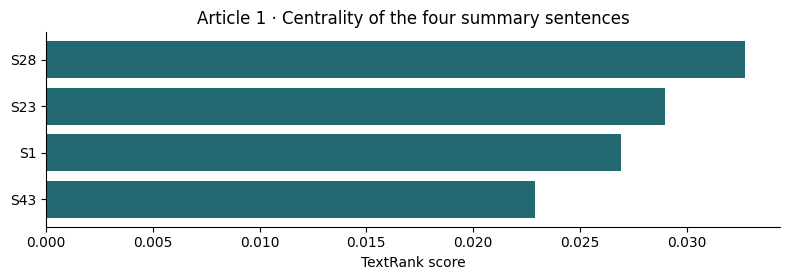

In [4]:
sentences = articles.at[1, 'sentences']
X = vectorizer().fit_transform(sentences)
similarity = (X @ X.T).toarray()
np.fill_diagonal(similarity, 0)
n = len(sentences)
sums = similarity.sum(axis=1, keepdims=True)
transition = np.divide(similarity, sums, out=np.full((n, n), 1/n), where=sums != 0)
rank = np.full(n, 1/n)
for iteration in range(150):
    updated = 0.15 / n + 0.85 * transition.T @ rank
    if np.abs(updated - rank).sum() < 1e-9:
        rank = updated
        break
    rank = updated
eligible = [i for i, s in enumerate(sentences) if 8 <= len(s.split()) <= 65 and s.endswith(('.', '!', '?'))]
chosen = []
for _ in range(4):
    best = max((i for i in eligible if i not in chosen),
               key=lambda i: rank[i]/rank.max() - 0.65 * max((similarity[i,j] for j in chosen), default=0))
    chosen.append(best)
for i in sorted(chosen):
    print(f'S{i+1}: {sentences[i]}\n')
order = sorted(chosen, key=lambda i: rank[i])
fig, ax = plt.subplots(figsize=(8, 2.9))
ax.barh([f'S{i+1}' for i in order], rank[order], color='#236971')
ax.set(title='Article 1 · Centrality of the four summary sentences', xlabel='TextRank score')
ax.spines[['top','right']].set_visible(False)
fig.tight_layout()
plt.show()

## 3.4 · Articles 2–5: aggregate topic-based summarisation


In [5]:
passages = pd.DataFrame([{'article': i, 'passage': ' '.join(ss[start:start+6])}
                         for i, ss in articles.loc[2:, 'sentences'].items()
                         for start in range(0, len(ss), 6)])
tfidf = vectorizer(min_df=2)
P = tfidf.fit_transform(passages.passage)
nmf = NMF(n_components=4, init='nndsvda', random_state=42, max_iter=800)
W = nmf.fit_transform(P)
relative = normalize(W * np.linalg.norm(nmf.components_, axis=1), norm='l1')
terms = tfidf.get_feature_names_out()
topic_names = []
for j, weights in enumerate(nmf.components_):
    words = terms[weights.argsort()[::-1][:7]]
    topic_names.append(words[0])
    print(f'T{j+1}:', ', '.join(words))
profiles = pd.DataFrame(relative, index=passages.article, columns=topic_names).groupby(level=0).mean()
print('\nMean topic weights (%)\n', profiles.mul(100).round(1).to_string())
print('\nEqual-article aggregate (%)\n', profiles.mean().mul(100).round(1).to_string())
for i, row in profiles.iterrows():
    j = row.to_numpy().argmax()
    ss = [s for s in articles.at[i, 'sentences'] if 10 <= len(s.split()) <= 55 and s.endswith('.')]
    scores = tfidf.transform(ss) @ normalize(nmf.components_[j:j+1]).T
    print(f'\nArticle {i} | {topic_names[j]} | {ss[int(scores.argmax())]}')

T1: triangulation, data, methods, denzin, multiple, methodological triangulation, mixed
T2: alpha, cronbach, cronbach alpha, instrument, science, reliability, items
T3: development, research, developmental, instructional, design, developmental research, process
T4: reflexivity, researcher, personal, experience, experiences, research, participants

Mean topic weights (%)
          triangulation  alpha  development  reflexivity
article                                                
2                  1.7    1.9          1.2         95.2
3                  1.5    2.2         92.0          4.3
4                  1.5   92.4          3.5          2.6
5                 78.9    2.2          3.5         15.4

Equal-article aggregate (%)
 triangulation    20.9
alpha            24.7
development      25.1
reflexivity      29.4

Article 2 | reflexivity | This article addresses potential effects on reflexivity of researcher’s social position (e.g. gender, age, race, immigration status, sexual orien

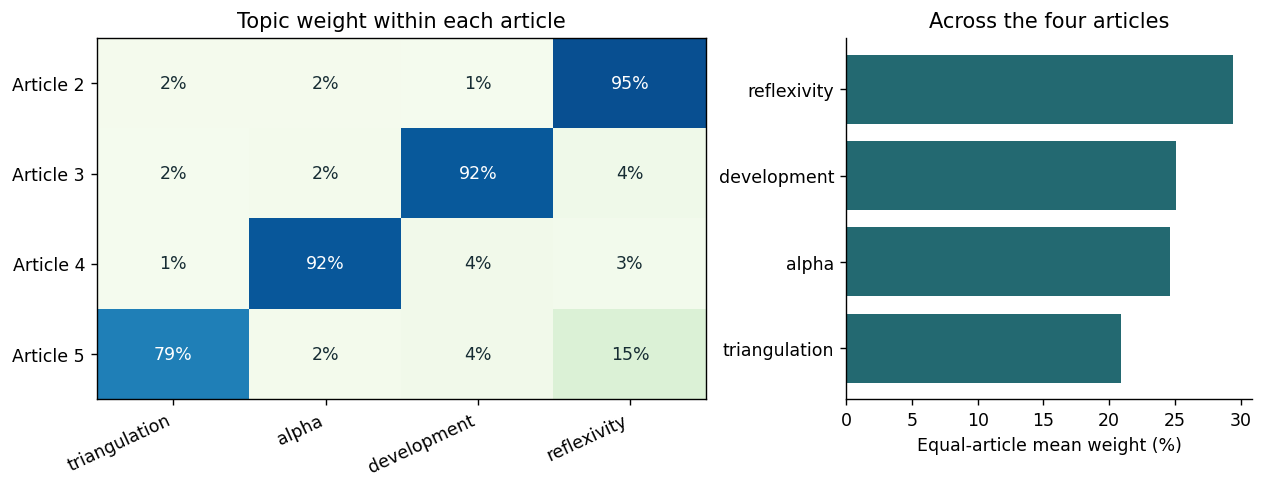

In [ ]:
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8), layout='constrained',
                                 gridspec_kw={'width_ratios': [1.5, 1]})
data = profiles.to_numpy()*100
left.imshow(data, cmap='GnBu', vmin=0, vmax=100, aspect='auto')
left.set_xticks(range(4), profiles.columns, rotation=25, ha='right')
left.set_yticks(range(4), [f'Article {i}' for i in profiles.index])
left.set_title('Topic weight within each article')
for r in range(4):
    for c in range(4):
        left.text(c, r, f'{data[r,c]:.0f}%', ha='center', va='center',
                  color='white' if data[r,c]>65 else '#162c33')
avg = profiles.mean().mul(100).sort_values()
right.barh(avg.index, avg.values, color='#236971')
right.set(title='Across the four articles', xlabel='Equal-article mean weight (%)')
right.spines[['top','right']].set_visible(False)
plt.show()

**Aggregate summary.** Together the four articles ask what makes research evidence trustworthy. Berger (article 2) examines how researchers’ insider or outsider positions influence interviews and interpretation, and presents reflexivity as a way to examine those influences. Richey, Klein and Nelson (article 3) distinguish creating an instructional product from systematically studying its design, development and evaluation. Article 4 shows why a high Cronbach’s alpha, on its own, cannot establish that a scale measures one construct or is suitable for its purpose. Fusch, Fusch and Ness (article 5) discuss how multiple sources, investigators, theories or methods can illuminate bias and deepen interpretation. The cross-article theme is the need to explain how evidence was produced and what conclusions it can support.

**Scope.** Some supplied texts end mid-discussion, including a mid-word ending in article 2. Summaries refer to the supplied extracts. Topic prevalence and a publication trend are different measurements. Tracking an AI trend would require AI-relevant documents, reliable dates and comparable coverage over time.